### Так, я только начал изучать pytorch и хочу попробовать сделать определитель машин.

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("eduardo4jesus/stanford-cars-dataset")
print("Датасет успешно скачан в папку:", dataset_path)

Using Colab cache for faster access to the 'stanford-cars-dataset' dataset.
Датасет успешно скачан в папку: /kaggle/input/stanford-cars-dataset


### Загрузка необходимых библиотек

In [ ]:
import torch # Главная библиотека
from torch import nn # Используется для создания слоев и функции потерь
from torch.optim import Adam # Оптимизатор Adam
import torchvision.transforms as transforms # Функции трансформации для изменения и предобработки всех изображений
from torchvision import models # Импорт предобученных моделей из библиотеки PyTorch
from torch.utils.data import Dataset, DataLoader # Классы Dataset и DataLoader для создания объектов данных
from sklearn.preprocessing import LabelEncoder # Кодировщик меток для преобразования строковых классов в числа
import matplotlib.pyplot as plt # Используется для визуализации изображений и построения графиков обучения
from PIL import Image # Используется для чтения изображений из директории
import pandas as pd # Используется для чтения/создания таблиц (csv) и обработки табличных данных
import numpy as np # Предобработка и численные/математические операции
import os # Используется для работы с путями к изображениям в директории

device = "cuda" if torch.cuda.is_available() else "cpu" # Определяем GPU, если доступен, иначе используем CPU (замените cuda на mps, если у вас Mac)


### Смотрим на обучающую выборку, чтобы посмотреть категорию и сравнить с ней образец машины.

In [5]:
import scipy.io # для чтения формата mat
import pandas as pd

base_dir = "/kaggle/input/stanford-cars-dataset"

meta = scipy.io.loadmat(f"{base_dir}/car_devkit/devkit/cars_meta.mat")
annos = scipy.io.loadmat(f"{base_dir}/car_devkit/devkit/cars_train_annos.mat")

class_names = [c[0] for c in meta["class_names"][0]]

data = [
    (item["fname"][0], class_names[int(item["class"][0][0]) - 1])
    for item in annos["annotations"][0]
]

data_df = pd.DataFrame(data, columns=["image:FILE", "category"])
data_df["image:FILE"] = f"{base_dir}/cars_train/cars_train/" + data_df["image:FILE"]

print("Data shape is: ", data_df.shape)
print()
data_df.head()


Data shape is:  (8144, 2)



,image:FILE,category
0,/kaggle/input/stanford-cars-dataset/cars_train...,Audi TTS Coupe 2012
1,/kaggle/input/stanford-cars-dataset/cars_train...,Acura TL Sedan 2012
2,/kaggle/input/stanford-cars-dataset/cars_train...,Dodge Dakota Club Cab 2007
3,/kaggle/input/stanford-cars-dataset/cars_train...,Hyundai Sonata Hybrid Sedan 2012
4,/kaggle/input/stanford-cars-dataset/cars_train...,Ford F-450 Super Duty Crew Cab 2012


### Смотри на все категории

In [8]:
print("Классы: ")
print(data_df["category"].unique())
print()
print("Распределение по классам: ")
print(data_df["category"].value_counts())

Classes are: 
[np.str_('Audi TTS Coupe 2012') np.str_('Acura TL Sedan 2012')
 np.str_('Dodge Dakota Club Cab 2007')
 np.str_('Hyundai Sonata Hybrid Sedan 2012')
 np.str_('Ford F-450 Super Duty Crew Cab 2012')
 np.str_('Geo Metro Convertible 1993') np.str_('Dodge Journey SUV 2012')
 np.str_('Dodge Charger Sedan 2012')
 np.str_('Mitsubishi Lancer Sedan 2012')
 np.str_('Chevrolet Traverse SUV 2012') np.str_('Buick Verano Sedan 2012')
 np.str_('Toyota Sequoia SUV 2012') np.str_('Hyundai Elantra Sedan 2007')
 np.str_('Dodge Caravan Minivan 1997') np.str_('Volvo C30 Hatchback 2012')
 np.str_('Plymouth Neon Coupe 1999')
 np.str_('Chevrolet Malibu Sedan 2007')
 np.str_('Volkswagen Beetle Hatchback 2012')
 np.str_('Chevrolet Corvette Ron Fellows Edition Z06 2007')
 np.str_('Chrysler 300 SRT-8 2010') np.str_('BMW M6 Convertible 2010')
 np.str_('GMC Yukon Hybrid SUV 2012')
 np.str_('Nissan Juke Hatchback 2012') np.str_('Volvo 240 Sedan 1993')
 np.str_('Suzuki SX4 Sedan 2012')
 np.str_('Dodge Ram 

In [9]:
train=data_df.sample(frac=0.8,random_state=7) # Тренировочный датасет 80%
test=data_df.drop(train.index) # тест будет 20 %

### Этот блок отвечает за превращение сырых картинок и текстовых названий машин в числа, которые понимает видеокарта и нейросеть PyTorch.

In [43]:
label_encoder = LabelEncoder() # Кодировщик меток
label_encoder.fit(data_df['category']) # Обучаем кодировщик один раз на всех классах
# нейросеть не понимает разные размеры картинок, так что приводим их к единому масштабу
transform = transforms.Compose([
    transforms.Resize((224, 224)), # Единый размер для ConvNeXt
    transforms.ToTensor(), # Переводит картинку в тензор со значениями от 0 до 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Нормализация для предобученной модели(написано в документации, это вообщем стандарт)
])
# Это класс-обертка для PyTorch, который объясняет программе, откуда брать данные и как выдавать их по одному во время обучения.
class CustomImageDataset(Dataset):
  def __init__(self, dataframe, transform=None):# сохраняет переданную таблицу и правила обработки
    self.dataframe = dataframe
    self.transform = transform
    # сразу переводит весь столбец с названиями машин в числа
    self.labels = torch.tensor(label_encoder.transform(dataframe['category'])).to(device)

  def __len__(self):
    return self.dataframe.shape[0]

  def __getitem__(self, idx): # Выдача одной картинки по номеру idx
    img_path = self.dataframe.iloc[idx, 0]# берет картинку
    label = self.labels[idx]# правильный номер машины
    # берет файл с диска и переводит в 3 цветовых канала
    image = Image.open(img_path).convert('RGB') # нужно, чтобы случайная картинка с 1 каналом ничего не сломала
    if self.transform:
      image = self.transform(image).to(device)

    return image, label


### Применяем то, что сделали выше. Сами по себе train и test из pandas просто текст для pytorch, поэтому мы оборачиваем их в наш класс и тем самым pytorch понимает как с ними работать.

In [62]:
train_dataset = CustomImageDataset(dataframe=train, transform=transform)
test_dataset = CustomImageDataset(dataframe=test, transform=transform)

### Здесь видно, что картинки теперь вот такого цвета, но это нужно, чтобы предобученная модель отлично определяла характерные черты.

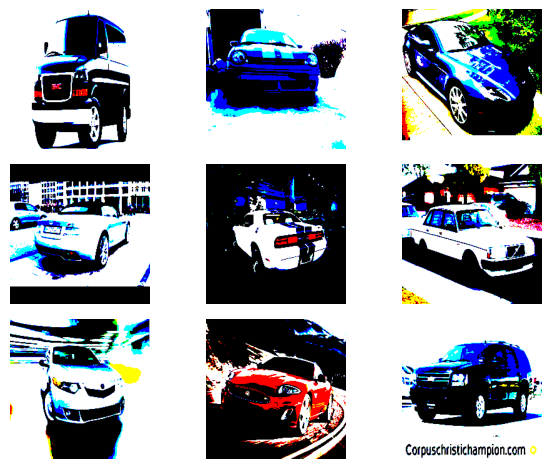

In [45]:
n_rows = 3
n_cols = 3
f, axarr = plt.subplots(n_rows, n_cols)
for row in range(n_rows):
    for col in range(n_cols):
        image = train_dataset[np.random.randint(0,train_dataset.__len__())][0].cpu()
        axarr[row, col].imshow((image*255).squeeze().permute(1,2,0))
        axarr[row, col].axis('off')

plt.tight_layout()
plt.show()

### Настройка гиперпараметров.

In [46]:
LR = 1e-4
BATCH_SIZE = 32
EPOCHS = 15

### А этот класс нужен, чтобы модель не принимала по одному экземпляру, а делала это пачками. Получается что DataLoader вызывает наш __getitem__ 32 раза подряд, склеивает картинку в 4-мерное пространство(32,3,224,224) и отправляет в модель за один раз.

In [47]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [48]:
# Загружаем ConvNeXt Tiny с готовыми весами
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)

# Считает, сколько уникальных моделей машин в таблице (получается 196).
num_classes = len(data_df["category"].unique())
# это нужно для того, чтобы вместо 1000 категорий сделать 196(изначально было 1000)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, num_classes)
model.to(device)# вся модель переносится на память видеокарты(cuda)


ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True, bias=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
 

### В итоге после всей сложной логике получается три последних блока.
* LayerNorm2d - финальная нормализация последних характеристик авто
* Flatten - вытягивает их в ровную строчку.
* Linear - итоговый вывод из 196 оценок.

In [49]:
model.classifier

Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=196, bias=True)
)

### Нужны две функции чтобы первый проверял с правильными ответами числа, а второй для оптимизации

In [50]:
# Определяем функцию потерь и оптимизатор
criterion = nn.CrossEntropyLoss() # Функция потерь (кросс-энтропия)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR) # Оптимизатор AdamW


### Цикл обучения

In [51]:
total_loss_train_plot = []
total_acc_train_plot = []

scaler = torch.amp.GradScaler('cuda')# защита от зануления моделью маленьких весов

for epoch in range(EPOCHS):
    model.train()
    total_acc_train = 0
    total_loss_train = 0

    for (inputs, labels) in train_loader:
        optimizer.zero_grad()# 1. стирает старые расчеты ошибок (градиенты) с предыдущей пачки, чтобы они не накапливались и не путали модель.
        with torch.amp.autocast('cuda'):# ускорение
            outputs = model(inputs)# матрица предсказаний(32,196) после прогонки 32 машин
            train_loss = criterion(outputs, labels)# вычисляет ошибку
        scaler.scale(train_loss).backward()# backpropagation
        scaler.step(optimizer)# включается оптимизатор(подкручивает веса модели)
        scaler.update()# автоподстройка множителя

        total_loss_train += train_loss.item()
        total_acc_train += (torch.argmax(outputs, axis=1) == labels).sum().item()# считает accuracy

    total_loss_train_plot.append(round(total_loss_train / 1000, 4))
    total_acc_train_plot.append(round(total_acc_train / (train_dataset.__len__()) * 100, 4))
    print(f'Epoch {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train / 100, 4)} Train Accuracy {round((total_acc_train) / train_dataset.__len__() * 100, 4)}%')
    print()


Epoch 1/15, Train Loss: 9.1282 Train Accuracy 14.9655%

Epoch 2/15, Train Loss: 4.1594 Train Accuracy 70.4988%

Epoch 3/15, Train Loss: 1.4501 Train Accuracy 92.3254%

Epoch 4/15, Train Loss: 0.5757 Train Accuracy 98.066%

Epoch 5/15, Train Loss: 0.2967 Train Accuracy 99.2786%

Epoch 6/15, Train Loss: 0.1767 Train Accuracy 99.6623%

Epoch 7/15, Train Loss: 0.1172 Train Accuracy 99.7698%

Epoch 8/15, Train Loss: 0.0945 Train Accuracy 99.8158%

Epoch 9/15, Train Loss: 0.0677 Train Accuracy 99.8926%

Epoch 10/15, Train Loss: 0.0567 Train Accuracy 99.8772%

Epoch 11/15, Train Loss: 0.0554 Train Accuracy 99.8005%

Epoch 12/15, Train Loss: 0.0384 Train Accuracy 99.9079%

Epoch 13/15, Train Loss: 0.0371 Train Accuracy 99.8619%

Epoch 14/15, Train Loss: 0.0281 Train Accuracy 99.8926%

Epoch 15/15, Train Loss: 0.0483 Train Accuracy 99.7391%



### Проверка на тесте

In [53]:
model.eval()# включаем все 100% нейронов

with torch.no_grad():# без подсчета градиентов(уже бессмысленно)
  total_loss_test = 0
  total_acc_test = 0
  for indx, (inputs, labels) in enumerate(test_loader):

    prediction = model(inputs)

    acc = (torch.argmax(prediction, axis=1) == labels).sum().item()
    total_acc_test += acc

print(f"Accuracy Score is: {round((total_acc_test / test_dataset.__len__()) * 100, 2)}%")


Accuracy Score is: 86.56%


Не плохой результат для такой сложной задачи и с таким маленьким датасетом.

### Смотрим на эволюцию модели

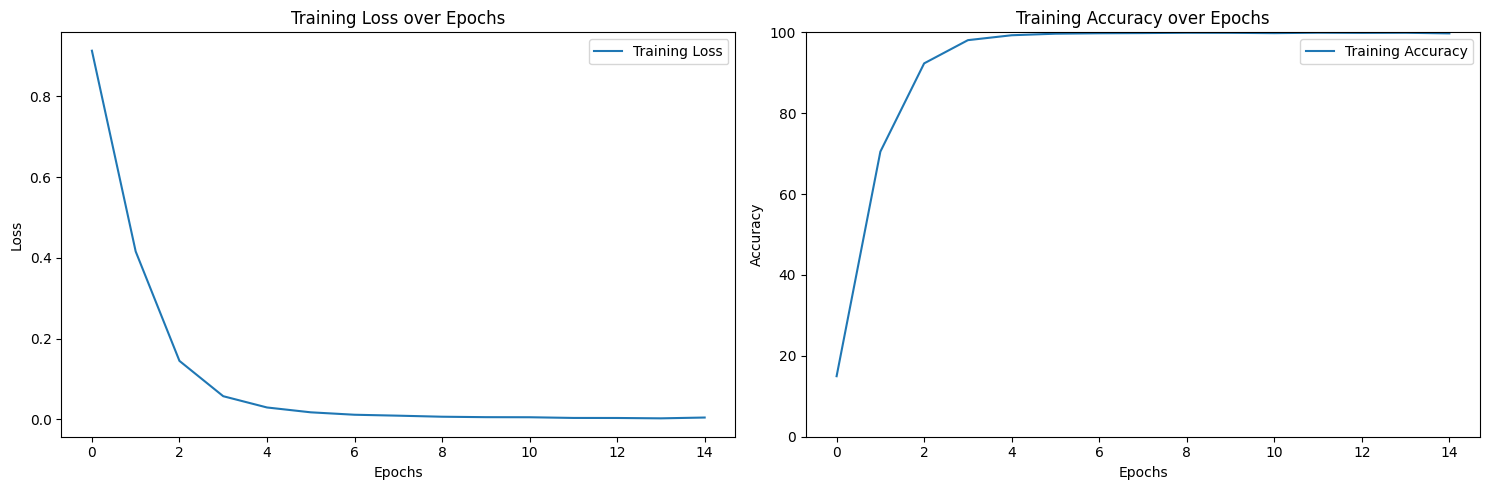

In [54]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].set_title('Training Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[1].set_ylim([0, 2])
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].set_title('Training Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_ylim([0, 100])
axs[1].legend()

plt.tight_layout()

plt.show()

### Сохранение модели

In [57]:
from google.colab import files

checkpoint = {
    'model_state_dict': model.state_dict(), # 28 миллионов обученных весов
    'class_names': list(label_encoder.classes_), # Список машин в правильном порядке а не числа
    'num_classes': len(label_encoder.classes_)# выход последнего слоя(196)
}

save_path = 'convnext_cars_196.pth'
torch.save(checkpoint, save_path)

files.download(save_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving 00016.jpg to 00016 (1).jpg


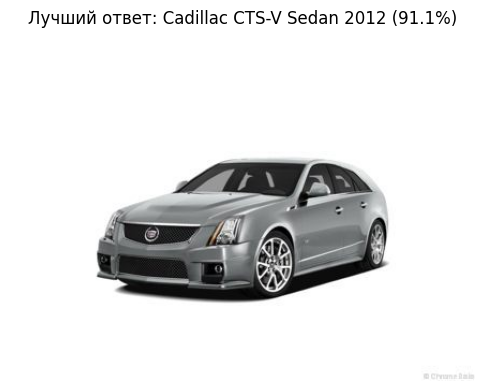

Топ-3 предсказания модели:
1. Cadillac CTS-V Sedan 2012 — 91.13%
2. Cadillac SRX SUV 2012 — 3.95%
3. BMW M5 Sedan 2010 — 0.58%


In [58]:
import torch.nn.functional as F # нужна функция softmax для перевода оценок в проценты

uploaded = files.upload()
img_path = next(iter(uploaded))

image = Image.open(img_path).convert('RGB')# переводим в цветной формат(если нужно)(3-мерный, чтобы все работало)
# transform(image) сжимает фото до 224x224 и нормализует цвета, получается (3,224,244)
input_tensor = transform(image).unsqueeze(0).to(device)# unsqueeze(0) делает одну пачку (1,3,224,244). Без этого ConvNeXt не примет данные. to(device) - отправляет картинку в память видеокарты.

model.eval()
with torch.no_grad():
    outputs = model(input_tensor)# прогоняет через всю модель и на выходе (1,196) и получается 196 сырых чисел(1,96; 1,54 к примеру и т.д)
    probabilities = F.softmax(outputs, dim=1)# превращаем в вероятность от 0 до 1(каждое число), сумма равна 1
    top3_prob, top3_idx = torch.topk(probabilities, 3)#находит 3 самые большие вероятности и порядковые номера классов этих машин

top3_prob = top3_prob[0].cpu()
top3_idx = top3_idx[0].cpu()

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis('off')
plt.title(f"Лучший ответ: {label_encoder.classes_[top3_idx[0]]} ({top3_prob[0].item()*100:.1f}%)")
plt.show()

print("Топ-3 предсказания модели:")
for i in range(3):
    car_name = label_encoder.classes_[top3_idx[i]]
    conf = top3_prob[i].item() * 100
    print(f"{i+1}. {car_name} — {conf:.2f}%")


Итоги проекта:
1. Данные: Загружен и обработан датасет Stanford Cars (8 144 изображения, 196 уникальных моделей автомобилей разных годов выпуска), разделенный на обучающую (80%) и тестовую (20%) выборки.
2. Архитектура и обучение: Использован метод Transfer Learning на базе современной сверточной сети ConvNeXt-Tiny с заменой выходного слоя под 196 классов. Обучение проводилось на GPU с применением оптимизатора AdamW (lr=1e-4) и ускорения смешанной точности (AMP / FP16) в течение 15 эпох.
3. Результаты:
	• Точность на обучающей выборке достигла 99.9%
	• Итоговая точность на незнакомых тестовых данных составила 86.56%
	• Модель успешно сохранена в файл convnext_cars_196.pth вместе со словарем классов и проверена на реальном изображении (уверенность в правильном классе — 91.13%).